### **Soil Moisture Prediction [XGBoost]**

**<u>Dataset I</u>**

Description: Predict soil moisture from sensor telemetry

Source: https://zenodo.org/records/10991581

In [ ]:
import random
import pandas as pd
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import math
import time
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

sns.set_style('darkgrid')

random.seed(42); np.random.seed(42); tf.random.set_seed(42)

In [ ]:
"""---------------------------------
Resources
------------------------------------"""
''''
[1] Cyclical time encoding: https://towardsdatascience.com/is-your-model-time-blind-the-case-for-cyclical-feature-encoding/

[2] XGBoost hyperparameters tuning: https://gist.github.com/fpleoni/c44c0c3654c12abe686a80937d9da200#file-xgboost_rscv-py


'''


"'\n[1] Cyclical time encoding https://towardsdatascience.com/is-your-model-time-blind-the-case-for-cyclical-feature-encoding/\n"

In [3]:
"""---------------------------------
Load dataset
------------------------------------"""

DATA = pd.read_csv('Edge_IoT_Predictive_Irrigation_Dataset.csv')
DATA["Timestamp"] = pd.to_datetime(DATA["Timestamp"])
DATA = DATA.sort_values(by='Timestamp')

DATA.head()
# DATA.dtypes

C:\Users\ptong\AppData\Local\Temp\ipykernel_9304\3060868569.py:6: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  DATA["Timestamp"] = pd.to_datetime(DATA["Timestamp"])


,Timestamp,Day,Time,Temperature_C,Humidity_pct,Soil_Moisture_pct,Light_Intensity,Pump_Status
537,2026-04-01 00:00:00,1,0:00,25.1,83,64.1,0,0
455,2026-04-01 00:30:00,1,0:30,25.0,84,63.4,0,0
456,2026-04-01 01:00:00,1,1:00,25.0,86,63.4,0,0
405,2026-04-01 01:30:00,1,1:30,25.0,87,62.8,0,0
436,2026-04-01 02:00:00,1,2:00,25.0,85,63.1,0,0


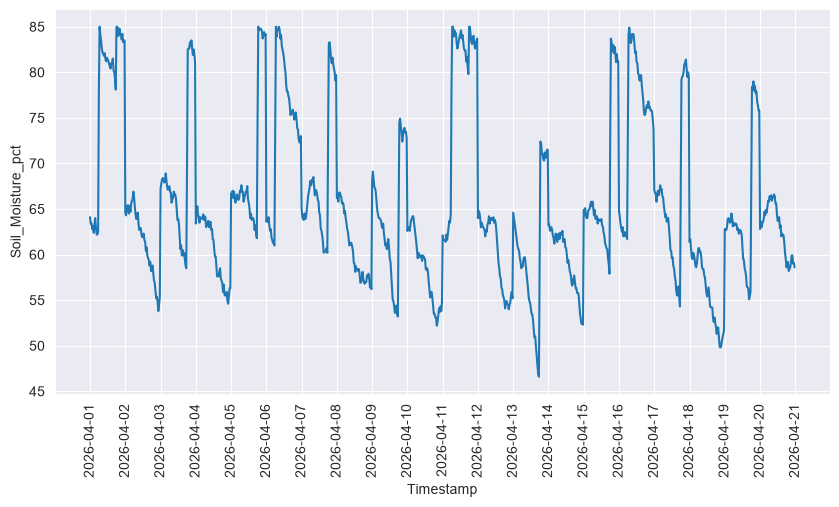

In [4]:
"""---------------------------------
Visualize
------------------------------------"""
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize = (10,5))
sns.lineplot(x='Timestamp', y='Soil_Moisture_pct', data=DATA)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.tick_params(axis='x', rotation=90)
ax.grid(True)
plt.show()

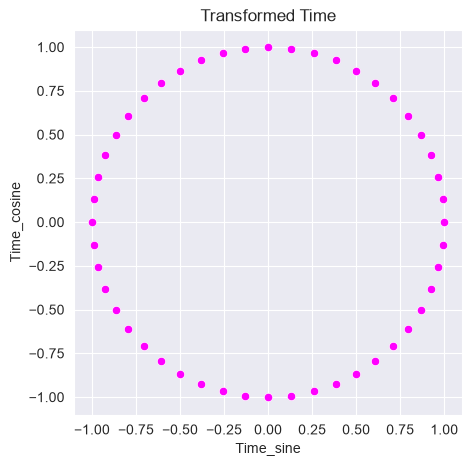

In [5]:
"""---------------------------------
Transform Time Column to Sine & Cosine
------------------------------------"""

DATA['Time'].dtypes # str
DATA['Time'] = pd.to_datetime(DATA['Time'], format='%H:%M')

DATA['Hour'] = DATA['Time'].dt.hour	+ DATA['Time'].dt.minute/60.0
# DATA['Hour'].head()

DATA['Time_sine'] = np.sin(2 * np.pi * DATA["Hour"]/24.0)
DATA['Time_cosine'] = np.cos(2 * np.pi * DATA["Hour"]/24.0)

fig, ax = plt.subplots(figsize=(5,5))
sns.scatterplot(x='Time_sine', y='Time_cosine', data=DATA, color='magenta')

ax.grid(True)
plt.title('Transformed Time')
plt.show()



In [6]:
"""---------------------------------
Create Sliding Windows
------------------------------------"""

def create_dataset(DATA, lookback=1):
    x, y = [], []

    for i in range(lookback, len(DATA)):
        window = DATA[(i- lookback):i, :]
        x.append(window.flatten())
        
        y.append(DATA[i, 0]) 

    return np.array(x), np.array(y)

In [ ]:
"""---------------------------------
Multivariate Architecture
------------------------------------"""
LOOKBACK = 24

FEATURES_INPUT = ['Soil_Moisture_pct','Time_sine','Time_cosine', 'Temperature_C', 'Humidity_pct', 'Light_Intensity']
DATA_TRANS = DATA[FEATURES_INPUT]
DATA_TRANS.head()

# x.shape

,Soil_Moisture_pct,Time_sine,Time_cosine,Temperature_C,Humidity_pct,Light_Intensity
537,64.1,0.000000,1.000000,25.1,83,0
455,63.4,0.130526,0.991445,25.0,84,0
456,63.4,0.258819,0.965926,25.0,86,0
405,62.8,0.382683,0.923880,25.0,87,0
436,63.1,0.500000,0.866025,25.0,85,0


In [8]:
"""---------------------------------
Split into Train-test
------------------------------------"""

# Specifying the start-end rows for train-test-val splits
SAMPLES = len(DATA)
TRAIN_END = int(SAMPLES*0.7)
VAL_END = int(SAMPLES*0.85)

# Convert to NumPy array for creating dataset
DATA_VALS = DATA_TRANS.values

X_train_xgb, y_train_xgb = create_dataset(DATA_VALS[:TRAIN_END], lookback=LOOKBACK)
X_test_xgb, y_test_xgb = create_dataset(DATA_VALS[VAL_END:SAMPLES], lookback=LOOKBACK)


In [ ]:
"""---------------------------------
Model Fitting
------------------------------------"""
split_series = TimeSeriesSplit(n_splits=5)

param_distributions = {"learning_rate": [0.1, 0.01, 0.001],
               "gamma" : [0.01, 0.1, 0.3, 0.5, 1, 1.5, 2],
               "max_depth": [2, 4, 7, 10],
               "colsample_bytree": [0.3, 0.6, 0.8, 1.0],
               "subsample": [0.2, 0.4, 0.5, 0.6, 0.7],
               "reg_alpha": [0, 0.5, 1],
               "reg_lambda": [1, 1.5, 2, 3, 4.5],
               "min_child_weight": [1, 3, 5, 7],
               "n_estimators": [100, 250, 500, 1000]}

xgb_base = xgb.XGBRegressor(random_state=42)
trainingtime_start = time.perf_counter()

random_search = RandomizedSearchCV(estimator=xgb_base, param_distributions = param_distributions, scoring = "f1_micro",
                             cv = 7, verbose = 1, random_state = 42)

random_search.fit(X_train_xgb, y_train_xgb)

print("Best Parameters found:")
print(random_search.best_params_)

final_xgb_regressor = random_search.best_estimator_
trainingtime_end = time.perf_counter()
training_duration = trainingtime_end - trainingtime_start

print(f"Training Time: {training_duration:.4f} seconds")

Fitting 7 folds for each of 10 candidates, totalling 70 fits


c:\Users\ptong\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py:956: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "c:\Users\ptong\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 945, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ptong\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py", line 80, in inner_f
    return f(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\ptong\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_scorer.py", line 322, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

Best Parameters found:
{'subsample': 0.6, 'reg_lambda': 1.5, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.6}
Training Time: 60.7689 seconds


In [ ]:
"""---------------------------------
Prediction
------------------------------------"""
y_pred_actual = final_xgb_regressor.predict(X_test_xgb)

y_test_actual = y_test_xgb

print(len(y_test_actual))

120


120


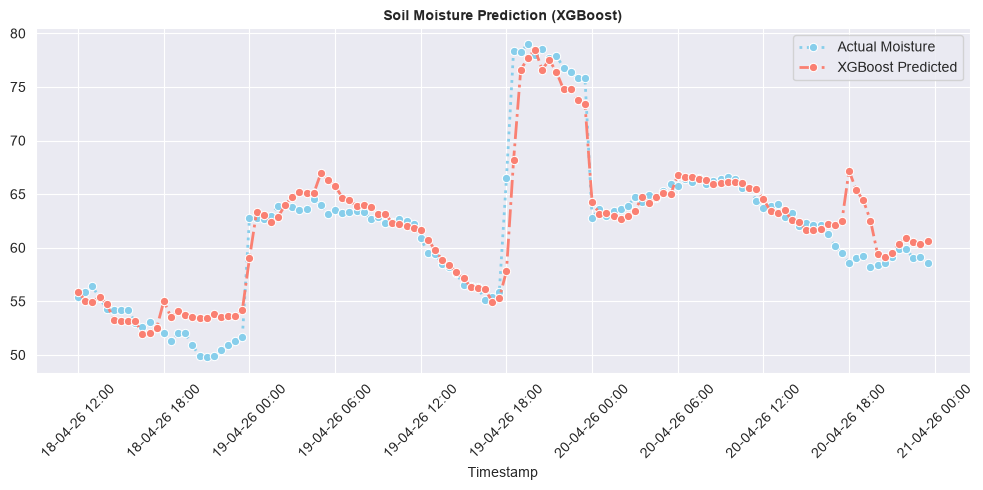

In [14]:
"""---------------------------------
Visualize
------------------------------------"""

DATETIME_TEST = DATA['Timestamp'].iloc[VAL_END+LOOKBACK:SAMPLES] # Offset first set of lookback
print(len(DATETIME_TEST))
fig, ax = plt.subplots(figsize = (10,5))
sns.lineplot(x=DATETIME_TEST, y=y_test_actual.flatten(), label='Actual Moisture', linestyle=':', color='skyblue', linewidth=2, marker="o")
sns.lineplot(x=DATETIME_TEST, y=y_pred_actual.flatten(), label='XGBoost Predicted', linestyle='-.', color='salmon', linewidth=2, marker="o")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%y %H:%M'))

plt.title('Soil Moisture Prediction (XGBoost)', fontsize=10, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [12]:
"""---------------------------------
Summary Results
------------------------------------"""

print(f"""
Metric       | Value
------------------------
MAE          | {round(mean_absolute_error(y_pred_actual, y_test_actual),2)}
MSE          | {round(mean_squared_error(y_pred_actual, y_test_actual),2)}
RMSE         | {round(math.sqrt(mean_squared_error(y_pred_actual, y_test_actual)),2)}
R2 score     | {round((r2_score(y_pred_actual, y_test_actual)),2)}
""")



Metric       | Value
------------------------
MAE          | 1.38
MSE          | 4.75
RMSE         | 2.18
R2 score     | 0.87

